# MOVIE GENRE CLASSIFICATION 
Code by Siddhartha Mettu

### Import Libraries

In [1]:
import pandas as pd
import numpy as np
import re
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, classification_report

from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression

### Load Dataset

In [2]:
train = pd.read_csv(r"C:\Users\Siddhartha Mettu\OneDrive\Desktop\Internship\MOVIE GENRE CLASSIFICATION\Genre Classification Dataset\train_data.txt", sep=" ::: ", engine='python',
                    names=["ID", "TITLE", "GENRE", "DESCRIPTION"])

test = pd.read_csv(r"C:\Users\Siddhartha Mettu\OneDrive\Desktop\Internship\MOVIE GENRE CLASSIFICATION\Genre Classification Dataset\test_data.txt", sep=" ::: ", engine='python',
                   names=["ID", "TITLE", "DESCRIPTION"])

## EDA (Exploratory Data Analysis)

### Basic Info

In [3]:
print(train.shape)
print(train.head())
print(train.isnull().sum())

(54214, 4)
   ID                             TITLE     GENRE  \
0   1      Oscar et la dame rose (2009)     drama   
1   2                      Cupid (1997)  thriller   
2   3  Young, Wild and Wonderful (1980)     adult   
3   4             The Secret Sin (1915)     drama   
4   5            The Unrecovered (2007)     drama   

                                         DESCRIPTION  
0  Listening in to a conversation between his doc...  
1  A brother and sister with a past incestuous re...  
2  As the bus empties the students for their fiel...  
3  To help their unemployed father make ends meet...  
4  The film's title refers not only to the un-rec...  
ID             0
TITLE          0
GENRE          0
DESCRIPTION    0
dtype: int64


### Genre Distribution


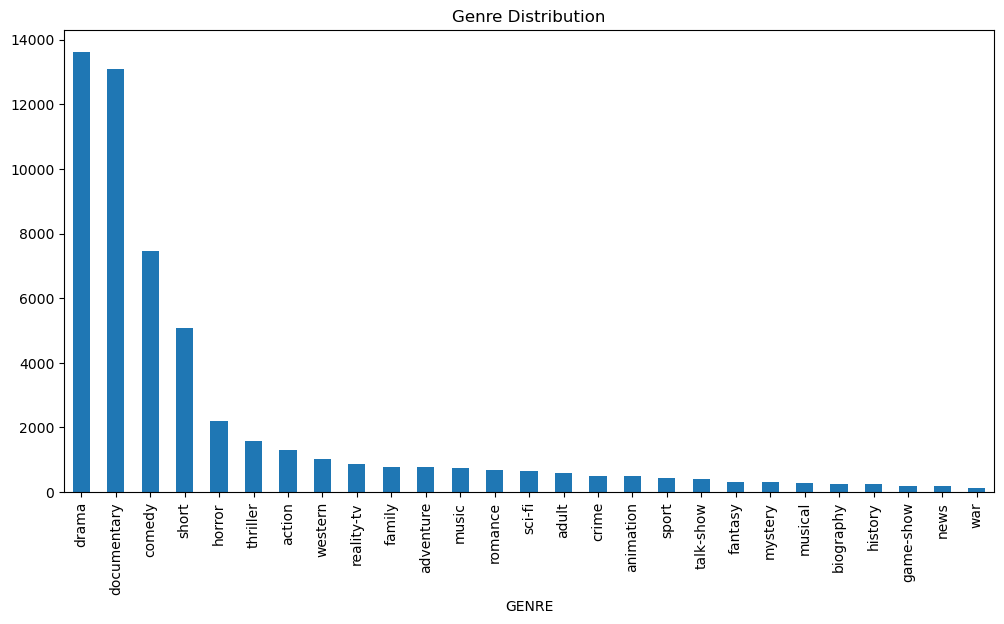

In [4]:
plt.figure(figsize=(12,6))
train['GENRE'].value_counts().plot(kind='bar')
plt.title("Genre Distribution")
plt.show()

### Text Length Analysis

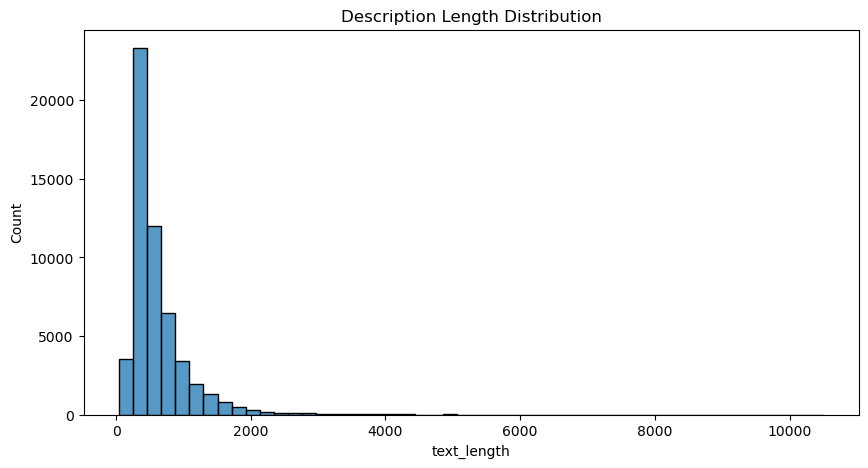

In [5]:
train['text_length'] = train['DESCRIPTION'].apply(len)

plt.figure(figsize=(10,5))
sns.histplot(train['text_length'], bins=50)
plt.title("Description Length Distribution")
plt.show()

### Top Words

In [6]:
from collections import Counter

all_words = " ".join(train['DESCRIPTION']).split()
common_words = Counter(all_words).most_common(20)

print(common_words)

[('the', 297037), ('and', 186490), ('of', 166166), ('a', 162476), ('to', 156758), ('in', 97343), ('is', 80742), ('his', 64294), ('with', 49318), ('her', 41816), ('for', 39575), ('that', 39434), ('on', 33930), ('he', 33776), ('The', 33113), ('as', 31023), ('their', 30849), ('by', 29951), ('an', 27223), ('from', 27183)]


### Description Length vs Genre

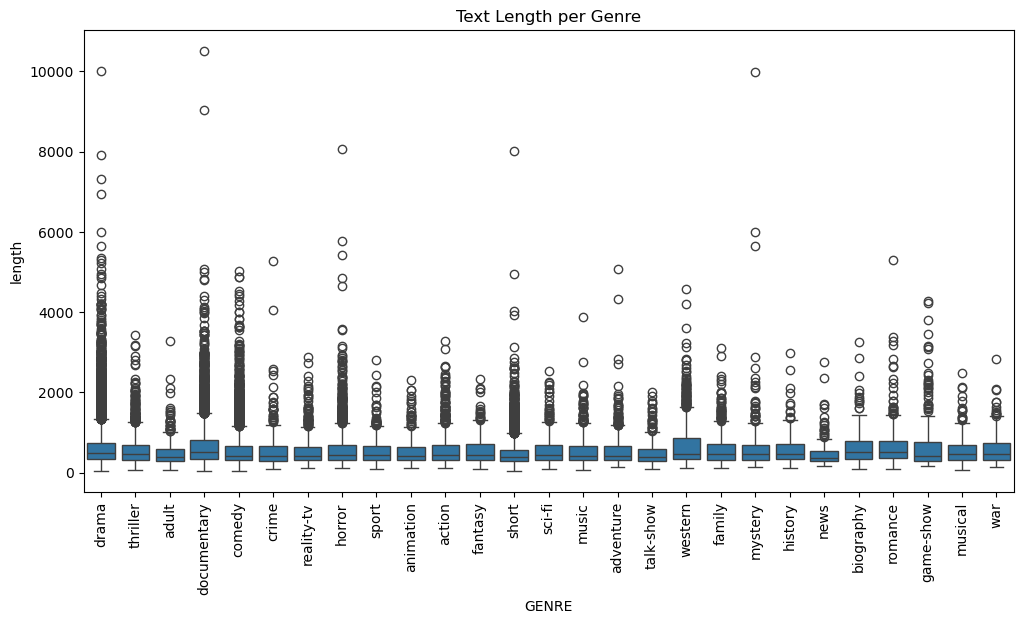

In [7]:
train['length'] = train['DESCRIPTION'].apply(len)

plt.figure(figsize=(12,6))
sns.boxplot(x='GENRE', y='length', data=train)
plt.xticks(rotation=90)
plt.title("Text Length per Genre")
plt.show()

### WordCloud per Genre

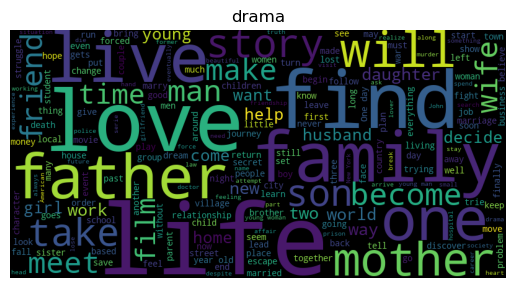

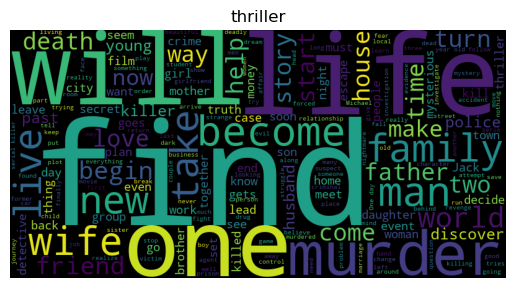

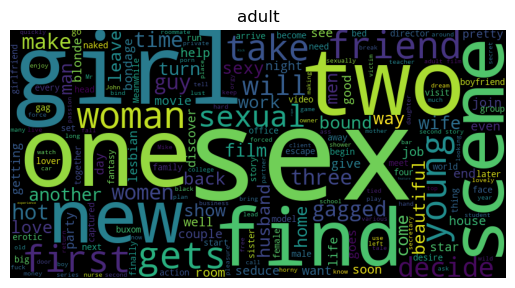

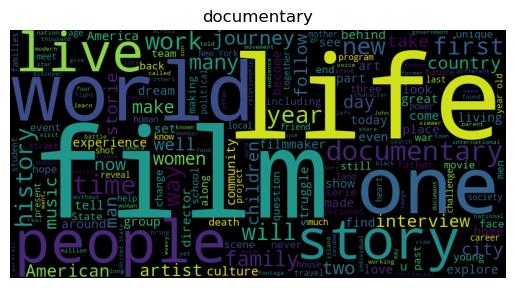

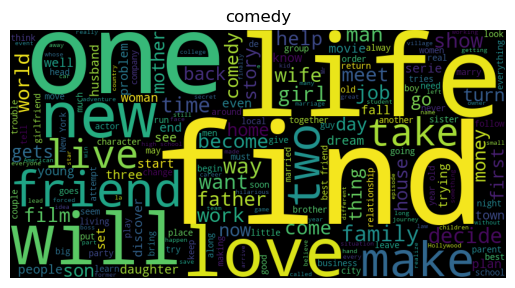

In [8]:
from wordcloud import WordCloud

for genre in train['GENRE'].unique()[:5]:
    text = " ".join(train[train['GENRE']==genre]['DESCRIPTION'])
    
    wc = WordCloud(width=800, height=400).generate(text)
    
    plt.imshow(wc)
    plt.title(genre)
    plt.axis('off')
    plt.show()

### N-gram Analysis

In [9]:
from sklearn.feature_extraction.text import CountVectorizer

cv = CountVectorizer(ngram_range=(2,2), stop_words='english')
X_ngram = cv.fit_transform(train['DESCRIPTION'])

sum_words = X_ngram.sum(axis=0)
words_freq = [(word, sum_words[0, idx]) for word, idx in cv.vocabulary_.items()]
words_freq = sorted(words_freq, key=lambda x: x[1], reverse=True)[:20]

print(words_freq)

[('year old', 2812), ('new york', 1907), ('high school', 1170), ('young man', 1166), ('young woman', 1024), ('falls love', 996), ('tells story', 943), ('best friend', 902), ('years later', 871), ('years ago', 863), ('los angeles', 818), ('united states', 802), ('small town', 737), ('world war', 623), ('york city', 580), ('fall love', 525), ('years old', 498), ('young girl', 472), ('award winning', 467), ('real life', 443)]


### Correlation Heatmap

<Axes: xlabel='length', ylabel='GENRE'>

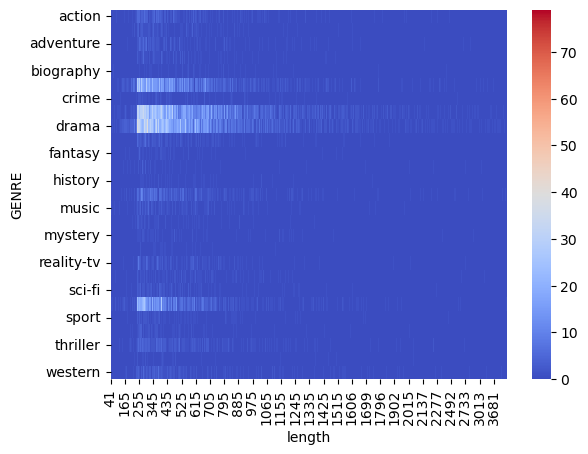

In [10]:
sns.heatmap(pd.crosstab(train['GENRE'], train['length']), cmap='coolwarm')

## Text Preprocessing

In [12]:
def clean_text(text):
    text = text.lower()
    text = re.sub(r'[^a-zA-Z]', ' ', text)
    text = re.sub(r'\s+', ' ', text)
    return text

train['clean_text'] = train['DESCRIPTION'].apply(clean_text)
test['clean_text'] = test['DESCRIPTION'].apply(clean_text)

### Most Frequent Words per Genre

In [13]:
for genre in train['GENRE'].unique()[:3]:
    words = " ".join(train[train['GENRE']==genre]['clean_text']).split()
    freq = pd.Series(words).value_counts()[:10]
    print(f"\nTop words in {genre}:\n", freq)


Top words in drama:
 the    78503
a      51900
and    49394
to     47167
of     39927
in     30088
is     26374
his    25024
her    21600
he     16473
Name: count, dtype: int64

Top words in thriller:
 the    8740
a      6143
to     5148
and    4946
of     4027
is     2868
in     2836
his    2367
her    2027
he     1707
Name: count, dtype: int64

Top words in adult:
 the     2613
a       1833
and     1639
to      1427
in      1001
of       966
her      822
is       689
with     587
s        521
Name: count, dtype: int64


### Label Encoding

In [14]:
le = LabelEncoder()
train['GENRE_ENC'] = le.fit_transform(train['GENRE'])

## Feature Engineering (TF-IDF)

In [15]:
tfidf = TfidfVectorizer(
    max_features=20000,      # increase features
    ngram_range=(1,2),       # unigrams + bigrams
    stop_words='english',    # remove noise
    min_df=2,                # remove rare words
    max_df=0.9               # remove overly common words
)

X = tfidf.fit_transform(train['clean_text'])
y = train['GENRE_ENC']

### Train-Test Split

In [16]:
X_train, X_val, y_train, y_val = train_test_split(
    X, y, test_size=0.2, random_state=42
)

## Model Training

### Model 1: Naive Bayes

In [17]:
nb = MultinomialNB()
nb.fit(X_train, y_train)

y_pred_nb = nb.predict(X_val)

print("Naive Bayes Accuracy:", accuracy_score(y_val, y_pred_nb))

Naive Bayes Accuracy: 0.5022595222724339


### Model 2: Logistic Regression

In [18]:
lr = LogisticRegression(max_iter=200, class_weight='balanced')
lr.fit(X_train, y_train)

y_pred_lr = lr.predict(X_val)

print("Logistic Regression Accuracy:", accuracy_score(y_val, y_pred_lr))

Logistic Regression Accuracy: 0.4963570967444434


### Model 3: Support Vector Machine

In [19]:
from sklearn.svm import LinearSVC

svm = LinearSVC()
svm.fit(X_train, y_train)

y_pred = svm.predict(X_val)

print("SVM Accuracy:", accuracy_score(y_val, y_pred))

C:\Users\Siddhartha Mettu\anaconda3\Lib\site-packages\sklearn\svm\_classes.py:31: FutureWarning: The default value of `dual` will change from `True` to `'auto'` in 1.5. Set the value of `dual` explicitly to suppress the warning.
  warnings.warn(


SVM Accuracy: 0.5727197270128194


In [23]:
print(classification_report(y_val, y_pred_lr))

              precision    recall  f1-score   support

           0       0.36      0.48      0.41       263
           1       0.35      0.66      0.46       112
           2       0.19      0.32      0.23       139
           3       0.20      0.29      0.24       104
           4       0.06      0.11      0.08        61
           5       0.60      0.49      0.54      1443
           6       0.15      0.33      0.20       107
           7       0.81      0.60      0.69      2659
           8       0.71      0.42      0.53      2697
           9       0.13      0.31      0.18       150
          10       0.13      0.15      0.14        74
          11       0.63      0.72      0.67        40
          12       0.06      0.18      0.09        45
          13       0.57      0.73      0.64       431
          14       0.38      0.79      0.51       144
          15       0.12      0.22      0.15        50
          16       0.14      0.27      0.18        56
          17       0.18    

In [24]:
X_test = tfidf.transform(test['clean_text'])

test_preds = lr.predict(X_test)

test['PREDICTED_GENRE'] = le.inverse_transform(test_preds)

In [25]:
test[['ID', 'PREDICTED_GENRE']].to_csv("submission.csv", index=False)